# EDA: what the reviews look like

Only the 200k **train** sample is explored here. Validation is for choosing models and the 400k test set stays untouched until the end; it is only used by `reviews.data` to find reviews repeated across splits.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from reviews.scrub import excerpt

report = json.loads(Path("../data/processed/report.json").read_text())
train = pd.read_parquet("../data/processed/train.parquet")
train["sentiment"] = train["label"].map({0: "negative", 1: "positive"})
report["duplicates"], {k: v["rows"] for k, v in report["splits"].items()}

({'pool': 224400,
  'pool_in_test': 13,
  'pool_repeats': 5,
  'conflicting_labels_in_test': 0,
  'test_repeats': 11},
 {'train': 200000, 'validation': 20000, 'test': 400000})

## Duplicates across splits

Fewer than feared: of the 224,400 sampled train reviews, 13 also appear in the test set (after ignoring case, accents, punctuation and spacing) and 5 repeat within the sample. All were dropped. The test set has 11 repeats of its own, none with conflicting labels; it is left as it is. So duplicates won't inflate the scores here, unlike the prompt datasets in prompt-injection-guard.

In [2]:
train["sentiment"].value_counts(normalize=True).round(4)

sentiment
negative    0.5002
positive    0.4998
Name: proportion, dtype: float64

Balanced, by construction of the dataset. Accuracy is a fair headline number here.

## Length

In [3]:
train["chars"] = train["content"].str.len()
train["words"] = train["content"].str.split().str.len()
train.groupby("sentiment")[["chars", "words"]].describe(percentiles=[0.05, 0.5, 0.95]).T.round(0)

sentiment    negative  positive
chars count  100032.0   99968.0
      mean      422.0     389.0
      std       233.0     234.0
      min        36.0      36.0
      5%        119.0     110.0
      50%       379.0     332.0
      95%       868.0     854.0
      max      1008.0    1008.0
words count  100032.0   99968.0
      mean       77.0      71.0
      std        42.0      42.0
      min         5.0       1.0
      5%         22.0      21.0
      50%        70.0      61.0
      95%       157.0     154.0
      max       254.0     209.0

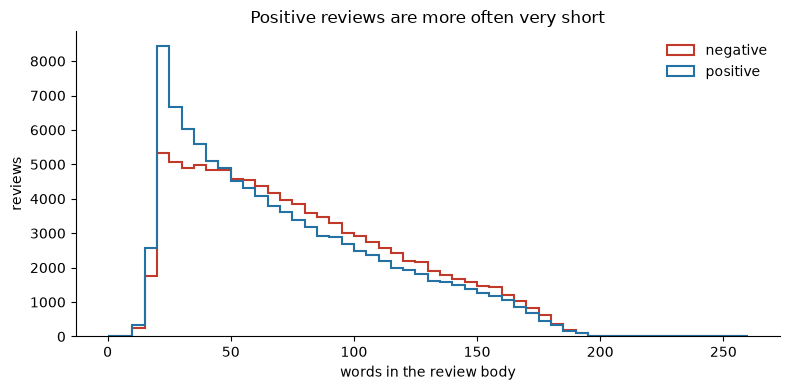

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, color in (("negative", "#c0392b"), ("positive", "#2471a3")):
    part = train.loc[train["sentiment"] == name, "words"]
    ax.hist(part, bins=range(0, 265, 5), histtype="step", color=color, label=name, lw=1.5)
ax.set_xlabel("words in the review body")
ax.set_ylabel("reviews")
ax.set_title("Positive reviews are more often very short")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("../reports/figures/review_length.png", dpi=150)

- Bodies run from 36 to about 1,000 characters. Very few come near the top, so it looks like a length limit when the dataset was built, not cut-off text.
- Negative reviews are longer: median 70 words against 61. That's a weak signal a model could pick up, so a length-only baseline is worth a line in the comparison (the same lesson as the prompt guard, where length alone reached AUC 0.87; here it will be far weaker).

In [5]:
from sklearn.metrics import roc_auc_score

# AUC of 'longer means negative'
round(roc_auc_score(train["label"] == 0, train["words"]), 3)

0.549

## Titles carry the verdict

In [6]:
title = train["title"].str.lower()
rows = []
for word in ["great", "excellent", "love", "not", "waste", "disappointed", "boring", "ok"]:
    has = title.str.contains(rf"\b{word}\b")
    share = round(train.loc[has, "label"].mean(), 3)
    rows.append({"title word": word, "reviews": int(has.sum()), "positive share": share})
pd.DataFrame(rows)

,title word,reviews,positive share
0,great,14784,0.862
1,excellent,3031,0.970
2,love,3048,0.873
3,not,16801,0.141
4,waste,2315,0.006
5,disappointed,1714,0.023
6,boring,1230,0.020
7,ok,802,0.229


Single words in the title already sort reviews: "waste" is positive 0.6% of the time, "excellent" 97%. "not" leans negative (14% positive) but not completely. The model will read `title. body` together (decision in ARCHITECTURE.md); day 4 checks how much the title adds.

## Negation, capitals and other text features

In [7]:
patterns = {
    "negation (not, n't, never, no)": r"\b(?:not|never|no)\b|n't",
    "word in capitals (4+ letters)": r"\b[A-Z]{4,}\b",
    "!! or more": r"!{2,}",
    "HTML entity (&quot; etc.)": r"&(?:\w+|#\d+);",
    "URL": r"https?://|www\.",
    "non-ASCII character": r"[^\x00-\x7f]",
}
text = train["title"] + " " + train["content"]
pd.DataFrame(
    {
        name: {
            "all %": text.str.contains(p).mean() * 100,
            "negative %": text[train.label == 0].str.contains(p).mean() * 100,
            "positive %": text[train.label == 1].str.contains(p).mean() * 100,
        }
        for name, p in patterns.items()
    }
).T.round(2)

,all %,negative %,positive %
"negation (not, n't, never, no)",64.32,77.34,51.30
word in capitals (4+ letters),16.91,19.27,14.55
!! or more,7.96,7.75,8.17
HTML entity (&quot; etc.),0.15,0.18,0.13
URL,0.16,0.17,0.15
non-ASCII character,0.33,0.27,0.38


- **Negation is everywhere**, more so in negative reviews. That's the bag-of-words weak spot: "not bad" and "not good" share both words. Word pairs (bigrams) on day 5 should help; the error analysis will count what's left.
- **Very little markup to clean**: HTML entities, tags and URLs are each under 0.2% of reviews. Day 3's cleaning can stay small (decode entities, normalise whitespace).
- **Non-ASCII is rare** and is mostly accented Latin letters (é, á, ó, ñ), mostly a few Spanish reviews (239, 0.12%, counted below). They stay in, and get counted in the error analysis.

In [8]:
accented = train[text.str.contains(r"[áéíóúñ]") & text.str.contains(r"\b(?:el|la|muy|que|es)\b")]
len(accented), round(len(accented) / len(train) * 100, 3)

(239, 0.12)

## A few short reviews from each class (scrubbed excerpts)

In [9]:
shortest = train.sort_values("chars").groupby("sentiment").head(3)
for _, row in shortest.iterrows():
    print(f"{row.sentiment:9s} | {excerpt(row.title + '. ' + row.content, 160)}")

positive  | Mens Premier Leather Single Layer Rainbow Sandals, Large 9.5-10.5, Sierra Brown. Excellent service and FAST SHIPMENT!
negative  | Actron CP9025 Honda, Nissan and Toyota OBD 1 Engine and ABS Trouble Code Scanner. Excellent price and quick shipping!!
negative  | I need to hear A Hunter not the band to evaluate for purchac. More vocals needed to reveiw adequately
negative  | Energizer ER-P730 Nickel-Metal Hydride Cordless Phone Battery. as advertised. fit perfectly , works great
positive  | Celtic Woman-A New Journey: Live at Slane Castle, Ireland. Wonderful, Marvelous. This is just great!!
positive  | Absolutely one of the most beautiful books I've ever read. Brilliant, romantic, moving, just wonderful


Two things show up even in six reviews:

- **Some labels contradict the text.** Two of the three shortest "negative" reviews say "Excellent price and quick shipping!!" and "fit perfectly, works great". The labels come from star ratings, not from reading the text, so some "mistakes" later will be the label's, not the model's. The error analysis (day 7) will count them.
- **Some titles are product names**, not review titles. Then the title says nothing about sentiment, and the body has to carry it.

## Takeaways for the next days

1. Duplicates are a non-issue in this sample (13 of 224k), so scores won't be inflated by repeats.
2. Classes are balanced, so accuracy works as the headline, with negative-class F1 next to it.
3. Cleaning can be minimal: hardly any HTML or URLs.
4. Titles are strong evidence; negation is common and will be the main source of mistakes for bag-of-words models.
5. Length is a weak signal (AUC 0.55); it gets a line in the baseline table.
6. Some labels are wrong (star rating vs text), which caps how good any model can look.